In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
import joblib

sns.set_theme(style="whitegrid")
df = pd.read_csv("../data/processed/superstore_clean.csv", parse_dates=["Order_Date"])
print("Rows:", len(df), "| Date range:", df["Order_Date"].min().date(), "to", df["Order_Date"].max().date())

Rows: 9800 | Date range: 2015-01-03 to 2018-12-30


In [2]:
CUTOFF     = pd.Timestamp("2018-01-01")         # features use ONLY history before this date
WINDOW_END = CUTOFF + pd.Timedelta(days=180)    # churn is observed in this future window

hist   = df[df["Order_Date"] < CUTOFF].copy()
future = df[(df["Order_Date"] >= CUTOFF) & (df["Order_Date"] < WINDOW_END)].copy()

print("History rows:", len(hist), "| Future-window rows:", len(future))
print("Customers with history:", hist["Customer_ID"].nunique())
print("Customers active in future window:", future["Customer_ID"].nunique())

History rows: 6542 | Future-window rows: 1148
Customers with history: 782
Customers active in future window: 427


In [3]:
cust = hist.groupby("Customer_ID").agg(
    First_Purchase = ("Order_Date", "min"),
    Last_Purchase  = ("Order_Date", "max"),
    Frequency      = ("Order_ID", "nunique"),   # F: how often
    Monetary       = ("Revenue", "sum"),        # M: how much
).reset_index()

cust["Recency"] = (CUTOFF - cust["Last_Purchase"]).dt.days   # R: days since last purchase (as of cutoff)
cust["Avg_Order_Value"] = cust["Monetary"] / cust["Frequency"]

# TARGET: did this customer buy anything in the NEXT 180 days?
active = future.groupby("Customer_ID")["Order_ID"].nunique().reset_index(name="Future_Orders")
cust = cust.merge(active, on="Customer_ID", how="left")
cust["Future_Orders"] = cust["Future_Orders"].fillna(0).astype(int)
cust["Churn_Status"] = (cust["Future_Orders"] == 0).astype(int)   # 1 = churned, 0 = retained

print(cust["Churn_Status"].value_counts())
cust.head()

Churn_Status
0    422
1    360
Name: count, dtype: int64


,Customer_ID,First_Purchase,Last_Purchase,Frequency,Monetary,Recency,Avg_Order_Value,Future_Orders,Churn_Status
0,AA-10315,2015-03-31,2017-03-03,4,5189.080,304,1297.270000,1,0
1,AA-10375,2015-04-21,2017-11-14,7,849.658,48,121.379714,0,1
2,AA-10480,2015-05-04,2017-08-26,3,1774.960,128,591.653333,1,0
3,AA-10645,2015-06-22,2017-09-04,5,5073.975,119,1014.795000,0,1
4,AB-10015,2015-02-18,2017-11-10,3,886.156,52,295.385333,0,1


In [4]:
FEATURES = ["Recency", "Frequency", "Monetary", "Avg_Order_Value"]   # never Customer_ID, never Churn_Status, never Future_Orders
X, y = cust[FEATURES], cust["Churn_Status"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

model = Pipeline([
    ("scaler", StandardScaler()),                 # puts all features on the same scale
    ("clf", LogisticRegression(max_iter=1000, random_state=42)),
])
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall   :", round(recall_score(y_test, y_pred), 3))

Accuracy : 0.52
Precision: 0.447
Recall   : 0.189


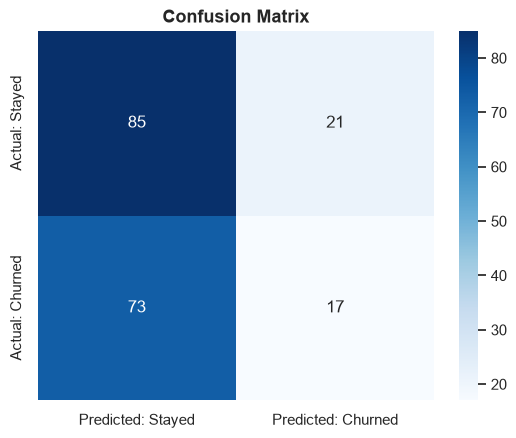

In [5]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted: Stayed", "Predicted: Churned"],
            yticklabels=["Actual: Stayed", "Actual: Churned"])
plt.title("Confusion Matrix", fontsize=13, fontweight="bold")
plt.show()

In [6]:
cust["Churn_Probability"] = model.predict_proba(cust[FEATURES])[:, 1]

def risk_level(p):
    if p < 0.40: return "Low Risk"
    if p < 0.70: return "Medium Risk"
    return "High Risk"

cust["Risk_Level"] = cust["Churn_Probability"].apply(risk_level)

risk_table = cust.sort_values("Churn_Probability", ascending=False)[
    ["Customer_ID", "Recency", "Frequency", "Monetary", "Churn_Probability", "Risk_Level"]]
print(risk_table["Risk_Level"].value_counts())
risk_table.head(20)

Risk_Level
Medium Risk    741
Low Risk        40
High Risk        1
Name: count, dtype: int64


,Customer_ID,Recency,Frequency,Monetary,Churn_Probability,Risk_Level
540,MW-18235,956,1,3333.900,0.812020,High Risk
353,JE-16165,27,1,2657.810,0.681073,Medium Risk
158,CM-12385,474,2,6682.260,0.679927,Medium Risk
691,SM-20320,372,3,24508.632,0.646990,Medium Risk
474,LW-16990,241,1,1691.608,0.619593,Medium Risk
422,KF-16285,297,2,4778.804,0.610025,Medium Risk
514,ML-17410,779,1,876.730,0.605878,Medium Risk
634,RH-19495,519,2,3491.712,0.599552,Medium Risk
377,JK-16090,620,1,893.090,0.589146,Medium Risk
84,BF-11275,1016,1,388.704,0.587764,Medium Risk


In [7]:
joblib.dump(model, "../models/churn_logreg.joblib")
risk_table.to_csv("../data/processed/customer_risk_table.csv", index=False)
print("Saved model + risk table.")

Saved model + risk table.
